# Classification de chats et de chiens avec un CNN

Ce notebook est construit progressivement. Chaque bloc de code doit avoir un objectif clair, être exécuté, puis être expliqué avec nos propres mots.

## 1. Localiser les données

Avant de construire un modèle, nous indiquons à Python où se trouvent les images. `Path` représente un chemin vers un fichier ou un dossier.

In [1]:
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_DIR = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)
DATA_DIR = PROJECT_DIR / "data"
TRAIN_DIR = DATA_DIR / "train"
VALIDATION_DIR = DATA_DIR / "validation"

print("Dossier du projet :", PROJECT_DIR)
print("Données trouvées :", DATA_DIR.exists())

Dossier du projet : C:\Users\assah\Desktop\projet ml i2
Données trouvées : True


## 2. Compter les images

`glob("*.jpg")` cherche les fichiers dont le nom se termine par `.jpg`. `len(...)` compte combien de fichiers ont été trouvés.

In [2]:
train_cats = len(list((TRAIN_DIR / "cats").glob("*.jpg")))
train_dogs = len(list((TRAIN_DIR / "dogs").glob("*.jpg")))
validation_cats = len(list((VALIDATION_DIR / "cats").glob("*.jpg")))
validation_dogs = len(list((VALIDATION_DIR / "dogs").glob("*.jpg")))

print("Entraînement - chats :", train_cats)
print("Entraînement - chiens :", train_dogs)
print("Validation - chats :", validation_cats)
print("Validation - chiens :", validation_dogs)

Entraînement - chats : 1000
Entraînement - chiens : 1000
Validation - chats : 500
Validation - chiens : 500


## 3. Séparer les données d’entraînement et de test

Nous gardons 80 % des 2 000 images pour l’apprentissage et 20 % pour le test final. `random_state=42` permet de retrouver exactement la même séparation à chaque exécution. `stratify` conserve la même proportion de chats et de chiens dans les deux groupes.

In [3]:
from sklearn.model_selection import train_test_split

all_train_files = sorted(TRAIN_DIR.glob("*/*.jpg"))
all_train_labels = [path.parent.name for path in all_train_files]

train_files, test_files = train_test_split(
    all_train_files,
    test_size=0.20,
    random_state=42,
    stratify=all_train_labels,
)

print("Images pour apprendre :", len(train_files))
print("Images gardées pour le test final :", len(test_files))

Images pour apprendre : 1600
Images gardées pour le test final : 400


### Vérifier l’équilibre de la séparation

`Counter` compte combien de chemins appartiennent au dossier `cats` et combien appartiennent au dossier `dogs`.

In [4]:
from collections import Counter

train_counts = Counter(path.parent.name for path in train_files)
test_counts = Counter(path.parent.name for path in test_files)

print("Apprentissage :", train_counts)
print("Test final :", test_counts)

Apprentissage : Counter({'dogs': 800, 'cats': 800})
Test final : Counter({'cats': 200, 'dogs': 200})


## 4. Ouvrir et observer une image

Nous ouvrons une image de l’ensemble d’apprentissage sans encore la modifier. Sa classe vient du nom de son dossier parent.

Classe : dogs
Taille (largeur, hauteur) : (258, 399)
Mode de couleur : RGB


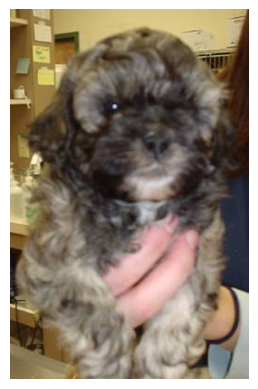

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

example_path = train_files[0]
example_image = Image.open(example_path)

print("Classe :", example_path.parent.name)
print("Taille (largeur, hauteur) :", example_image.size)
print("Mode de couleur :", example_image.mode)

plt.imshow(example_image)
plt.axis("off")
plt.show()

### Transformer l’image en tableau de nombres

Le modèle ne reçoit pas un objet `Image`. Il reçoit un tableau contenant les valeurs rouge, verte et bleue de chaque pixel.

In [6]:
import numpy as np

example_pixels = np.array(example_image)
print("Forme (hauteur, largeur, canaux) :", example_pixels.shape)

Forme (hauteur, largeur, canaux) : (399, 258, 3)


## 5. Comprendre le padding

Pour isoler l’effet du padding, nous ne choisissons pas encore une résolution finale. Nous prenons le côté le plus long de l’image et ajoutons seulement les pixels manquants autour du côté le plus court.

Avant : (258, 399)
Après padding : (399, 399)


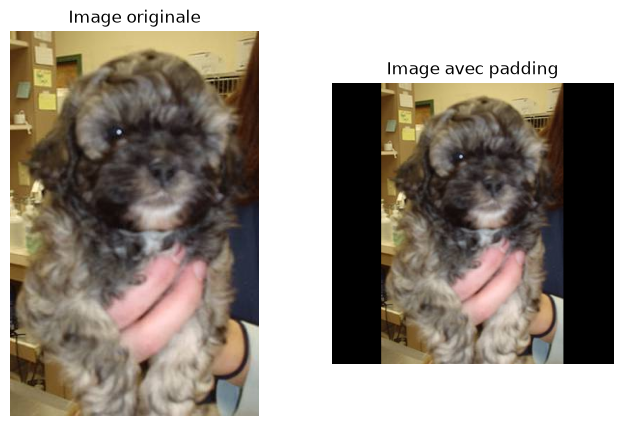

In [7]:
from PIL import ImageOps

square_side = max(example_image.size)
padded_image = ImageOps.pad(
    example_image,
    (square_side, square_side),
    color=(0, 0, 0),
)

print("Avant :", example_image.size)
print("Après padding :", padded_image.size)

figure, axes = plt.subplots(1, 2, figsize=(8, 5))
axes[0].imshow(example_image)
axes[0].set_title("Image originale")
axes[1].imshow(padded_image)
axes[1].set_title("Image avec padding")
for axis in axes:
    axis.axis("off")
plt.show()

### Créer une fonction réutilisable

La fonction suivante reçoit une image et une taille cible. Elle redimensionne l’image en conservant ses proportions, puis ajoute le padding nécessaire pour obtenir un carré.

In [8]:
def resize_with_padding(image, target_size):
    return ImageOps.pad(
        image,
        (target_size, target_size),
        method=Image.Resampling.BILINEAR,
        color=(0, 0, 0),
    )

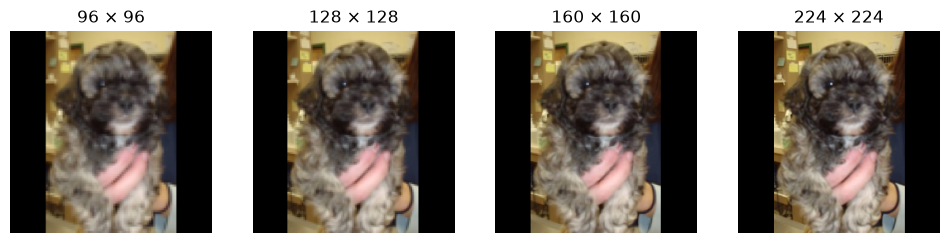

In [9]:
candidate_sizes = [96, 128, 160, 224]
figure, axes = plt.subplots(1, 4, figsize=(12, 4))

for axis, size in zip(axes, candidate_sizes):
    preview = resize_with_padding(example_image, size)
    axis.imshow(preview)
    axis.set_title(f"{size} × {size}")
    axis.axis("off")

plt.show()

## 6. Lire une image avec TensorFlow

Nous répétons une opération connue avec TensorFlow : lire le fichier JPEG, le décoder et obtenir un tableau de pixels RGB.

In [10]:
import tensorflow as tf

image_bytes = tf.io.read_file(str(example_path))
image_tensor = tf.image.decode_jpeg(image_bytes, channels=3)

print("Version de TensorFlow :", tf.__version__)
print("Forme :", image_tensor.shape)
print("Type des valeurs :", image_tensor.dtype)

Version de TensorFlow : 2.21.0
Forme : (399, 258, 3)
Type des valeurs : <dtype: 'uint8'>


### Appliquer le padding avec TensorFlow

Nous rendons cette image carrée en prenant son côté le plus long. Cette démonstration n’impose encore aucune résolution finale au projet.

In [11]:
height = image_tensor.shape[0]
width = image_tensor.shape[1]
square_side_tf = max(height, width)

padded_tensor = tf.image.resize_with_pad(
    image_tensor,
    target_height=square_side_tf,
    target_width=square_side_tf,
)

print("Avant :", image_tensor.shape)
print("Après padding :", padded_tensor.shape)

Avant : (399, 258, 3)
Après padding : (399, 399, 3)


### Normaliser les valeurs des pixels

Les valeurs RGB vont initialement de 0 à 255. Nous les divisons par 255 pour obtenir des valeurs entre 0 et 1, une échelle plus adaptée à l’entraînement du réseau.

In [12]:
normalized_tensor = tf.cast(padded_tensor, tf.float32) / 255.0

print("Avant normalisation :",
      tf.reduce_min(padded_tensor).numpy(),
      "à",
      tf.reduce_max(padded_tensor).numpy())
print("Après normalisation :",
      tf.reduce_min(normalized_tensor).numpy(),
      "à",
      tf.reduce_max(normalized_tensor).numpy())

Avant normalisation : 0.0 à 255.0
Après normalisation : 0.0 à 1.0


## 7. Regrouper plusieurs images dans un batch

Un **batch** est un petit lot d’images envoyé ensemble au réseau. Comme les images doivent pouvoir être empilées, elles ont toutes la même hauteur et la même largeur.

Nous utilisons ici 4 images et une taille de 128 × 128 uniquement pour comprendre la forme du batch. La résolution finale sera choisie plus tard en comparant plusieurs tailles.

In [13]:
def prepare_image(image_path, target_size):
    image_bytes = tf.io.read_file(str(image_path))
    image = tf.image.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize_with_pad(image, target_size, target_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

DEMO_BATCH_SIZE = 4
DEMO_TARGET_SIZE = 128  # taille temporaire pour la démonstration

demo_paths = train_files[:DEMO_BATCH_SIZE]
demo_images = tf.stack([
    prepare_image(path, DEMO_TARGET_SIZE)
    for path in demo_paths
])
demo_labels = tf.constant([
    0 if path.parent.name == "cats" else 1
    for path in demo_paths
])

print("Forme du batch d’images :", demo_images.shape)
print("Labels :", demo_labels.numpy())


Forme du batch d’images : (4, 128, 128, 3)
Labels : [1 1 0 0]


## 8. Créer les labels pour toutes les images

Le dossier parent donne la bonne réponse : `cats` devient 0 et `dogs` devient 1. Nous appliquons maintenant cette même règle aux ensembles d’apprentissage, de validation et de test. À cette étape, les images ne sont pas encore chargées en mémoire.

In [14]:
def path_to_label(path):
    return 0 if path.parent.name == "cats" else 1

validation_files = sorted(VALIDATION_DIR.glob("*/*.jpg"))

train_labels = [path_to_label(path) for path in train_files]
validation_labels = [path_to_label(path) for path in validation_files]
test_labels = [path_to_label(path) for path in test_files]

print("Apprentissage :", len(train_files), "adresses et", len(train_labels), "labels")
print("Validation :", len(validation_files), "adresses et", len(validation_labels), "labels")
print("Test final :", len(test_files), "adresses et", len(test_labels), "labels")


Apprentissage : 1600 adresses et 1600 labels
Validation : 1000 adresses et 1000 labels
Test final : 400 adresses et 400 labels


## 9. Préparer les couples image-label avec TensorFlow

`from_tensor_slices` associe chaque adresse à son label situé à la même position. Ensuite, `map` applique la fonction de préparation à chaque couple. Nous observons d’abord un seul résultat. La taille 128 × 128 reste temporaire.

In [15]:
def prepare_image_and_label(image_path, label, target_size):
    image_bytes = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize_with_pad(image, target_size, target_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

TEMPORARY_SIZE = 128
train_path_strings = [str(path) for path in train_files]

raw_train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_path_strings, train_labels)
)
prepared_train_dataset = raw_train_dataset.map(
    lambda path, label: prepare_image_and_label(
        path, label, TEMPORARY_SIZE
    )
)

for prepared_image, prepared_label in prepared_train_dataset.take(1):
    print("Forme d’une image préparée :", prepared_image.shape)
    print("Label conservé :", prepared_label.numpy())


Forme d’une image préparée : (128, 128, 3)
Label conservé : 1


## 10. Mélanger puis former des batches de 100 images

`shuffle` mélange les couples adresse-label avant l’apprentissage. `batch(100)` les regroupe ensuite par lots de 100. Comme le mélange précède `map`, TensorFlow mélange seulement les petites adresses avant de charger et préparer leurs pixels.

In [16]:
BATCH_SIZE = 100

train_dataset = raw_train_dataset.shuffle(
    buffer_size=len(train_files),
    seed=42,
)
train_dataset = train_dataset.map(
    lambda path, label: prepare_image_and_label(
        path, label, TEMPORARY_SIZE
    )
)
train_dataset = train_dataset.batch(BATCH_SIZE)

for batch_images, batch_labels in train_dataset.take(1):
    print("Forme du batch d’images :", batch_images.shape)
    print("Forme du batch de labels :", batch_labels.shape)
    print("Dix premiers labels :", batch_labels[:10].numpy())


Forme du batch d’images : (100, 128, 128, 3)
Forme du batch de labels : (100,)
Dix premiers labels : [1 1 0 0 1 1 0 0 0 0]


## 11. Construire les trois pipelines avec une seule fonction

La même fonction prépare les données d’apprentissage, de validation et de test. Seules les données d’apprentissage sont mélangées : la validation et le test gardent un ordre stable pour faciliter des comparaisons reproductibles.

In [17]:
def make_dataset(files, labels, target_size, batch_size, should_shuffle):
    path_strings = [str(path) for path in files]
    dataset = tf.data.Dataset.from_tensor_slices(
        (path_strings, labels)
    )

    if should_shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(files),
            seed=42,
        )

    dataset = dataset.map(
        lambda path, label: prepare_image_and_label(
            path, label, target_size
        )
    )
    dataset = dataset.batch(batch_size)
    return dataset

train_dataset = make_dataset(
    train_files, train_labels, TEMPORARY_SIZE, BATCH_SIZE, True
)
validation_dataset = make_dataset(
    validation_files, validation_labels, TEMPORARY_SIZE, BATCH_SIZE, False
)
test_dataset = make_dataset(
    test_files, test_labels, TEMPORARY_SIZE, BATCH_SIZE, False
)

print("Batches d’apprentissage :", train_dataset.cardinality().numpy())
print("Batches de validation :", validation_dataset.cardinality().numpy())
print("Batches de test final :", test_dataset.cardinality().numpy())


Batches d’apprentissage : 16
Batches de validation : 10
Batches de test final : 4


## 12. Construire le premier bloc du CNN

Ce premier bloc utilise 16 filtres de 3 × 3. Chaque filtre produit sa propre feature map. `padding="same"` conserve la hauteur et la largeur pendant la convolution, puis le MaxPooling 2 × 2 divise ces deux dimensions par deux. La résolution 128 × 128 est toujours temporaire.

In [18]:
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(TEMPORARY_SIZE, TEMPORARY_SIZE, 3))
x = layers.Conv2D(
    filters=16,
    kernel_size=(3, 3),
    padding="same",
    activation="relu",
    name="convolution_1",
)(inputs)
x = layers.MaxPooling2D(
    pool_size=(2, 2),
    name="pooling_1",
)(x)

first_block_model = keras.Model(inputs=inputs, outputs=x)
first_block_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_1 (Conv2D)          │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_1 (MaxPooling2D)        │ (None, 64, 64, 16)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

### Calcul des paramètres du premier bloc

Un filtre contient `3 × 3 × 3 = 27` poids : 3 × 3 positions et 3 canaux RGB. Il possède aussi un biais, soit 28 paramètres. Avec 16 filtres : `(3 × 3 × 3 + 1) × 16 = 448` paramètres. Le MaxPooling ne possède aucun paramètre à apprendre.

## 13. Construire le CNN complet à quatre blocs

Les quatre blocs utilisent respectivement 16, 32, 64 et 128 filtres. Quand la largeur et la hauteur diminuent grâce au pooling, le nombre de filtres augmente : le réseau conserve moins de positions, mais cherche davantage de caractéristiques différentes.

Après le quatrième bloc, `GlobalAveragePooling2D` résume chacune des 128 feature maps par une moyenne. Cette solution réduit fortement le nombre de paramètres par rapport à `Flatten`, tout en conservant une information par filtre.

In [19]:
def build_cnn(input_size):
    inputs = keras.Input(shape=(input_size, input_size, 3))
    x = inputs

    for block_number, number_of_filters in enumerate(
        [16, 32, 64, 128], start=1
    ):
        x = layers.Conv2D(
            filters=number_of_filters,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name=f"convolution_{block_number}",
        )(x)
        x = layers.MaxPooling2D(
            pool_size=(2, 2),
            name=f"pooling_{block_number}",
        )(x)

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)
    x = layers.Dense(
        units=64, activation="relu", name="dense_features"
    )(x)
    outputs = layers.Dense(
        units=1, activation="sigmoid", name="prediction"
    )(x)

    return keras.Model(inputs=inputs, outputs=outputs, name="cnn_chats_chiens")

keras.utils.set_random_seed(42)
model = build_cnn(TEMPORARY_SIZE)
model.summary()


Model: "cnn_chats_chiens"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_1 (Conv2D)          │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_1 (MaxPooling2D)        │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_2 (Conv2D)          │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_2 (MaxPooling2D)        │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_3 (Conv2D)          │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_3 (MaxPooling2D)        │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ convolution_4 (Conv2D)          │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_4 (MaxPooling2D)        │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,761 (413.13 KB)

 Trainable params: 105,761 (413.13 KB)

 Non-trainable params: 0 (0.00 B)

### Pourquoi utiliser une moyenne globale plutôt que Flatten ?

Après les quatre poolings, les données ont la forme 8 × 8 × 128. `Flatten` créerait 8 192 nombres avant la couche Dense. La moyenne globale crée seulement 128 nombres, un par feature map. Nous comparons ci-dessous le nombre de paramètres que demanderait la couche Dense dans les deux cas.

In [20]:
flatten_values = 8 * 8 * 128
global_average_values = 128
dense_units = 64

flatten_dense_parameters = (flatten_values + 1) * dense_units
global_average_dense_parameters = (global_average_values + 1) * dense_units
reduction_percent = (
    1 - global_average_dense_parameters / flatten_dense_parameters
) * 100

print("Dense après Flatten :", flatten_dense_parameters, "paramètres")
print("Dense après moyenne globale :", global_average_dense_parameters, "paramètres")
print(f"Réduction dans cette couche : {reduction_percent:.1f} %")


Dense après Flatten : 524352 paramètres
Dense après moyenne globale : 8256 paramètres
Réduction dans cette couche : 98.4 %


## 14. Configurer l’apprentissage

`BinaryCrossentropy` mesure l’écart entre le label réel 0/1 et la probabilité produite par la sigmoid. `Adam` utilise cette erreur pour ajuster progressivement les poids et les biais. Le taux d’apprentissage 0,001 contrôle la taille de chaque correction.

In [21]:
LEARNING_RATE = 0.001

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)


## 15. Entraîner la première baseline

La baseline utilise temporairement des images 128 × 128, des batches de 100 et 10 epochs, conformément à l’intervalle demandé. Le modèle apprend uniquement avec `train_dataset`. `validation_dataset` mesure son comportement après chaque epoch sans modifier ses paramètres. `test_dataset` reste intact pour l’évaluation finale.

In [22]:
import time

EPOCHS = 10
training_start = time.perf_counter()

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    shuffle=False,  # le Dataset est déjà mélangé
    verbose=2,
)

training_seconds = time.perf_counter() - training_start
print(f"Temps total : {training_seconds:.1f} secondes")


Epoch 1/10


16/16 - 5s - 307ms/step - accuracy: 0.5206 - loss: 0.6917 - val_accuracy: 0.5000 - val_loss: 0.6943


Epoch 2/10


16/16 - 4s - 257ms/step - accuracy: 0.5000 - loss: 0.6938 - val_accuracy: 0.5000 - val_loss: 0.6924


Epoch 3/10


...

Epoch 9/10


16/16 - 6s - 394ms/step - accuracy: 0.6263 - loss: 0.6328 - val_accuracy: 0.6310 - val_loss: 0.6217


Epoch 10/10


16/16 - 9s - 539ms/step - accuracy: 0.6194 - loss: 0.6380 - val_accuracy: 0.6530 - val_loss: 0.6217


Temps total : 55.0 secondes


## 16. Visualiser l’apprentissage et la validation

L’accuracy doit idéalement augmenter et la loss diminuer pour les deux ensembles. Un grand écart en faveur de l’apprentissage indiquerait un surapprentissage. Des performances faibles et proches sur les deux ensembles indiqueraient plutôt un sous-apprentissage.

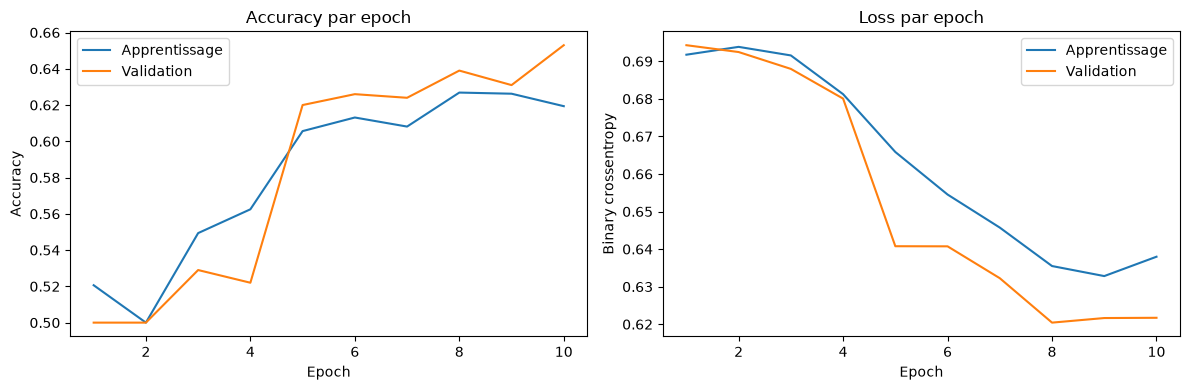

Meilleure epoch : 10
Meilleure accuracy de validation : 0.653


In [23]:
epochs_axis = range(1, EPOCHS + 1)
figure, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_axis, history.history["accuracy"], label="Apprentissage")
axes[0].plot(epochs_axis, history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy par epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(epochs_axis, history.history["loss"], label="Apprentissage")
axes[1].plot(epochs_axis, history.history["val_loss"], label="Validation")
axes[1].set_title("Loss par epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary crossentropy")
axes[1].legend()

plt.tight_layout()
plt.show()

best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1
best_validation_accuracy = max(history.history["val_accuracy"])
print("Meilleure epoch :", best_epoch)
print(f"Meilleure accuracy de validation : {best_validation_accuracy:.3f}")


## 17. Expérience contrôlée : jusqu’à 15 epochs

Les courbes de la baseline progressaient encore à la dixième epoch. Nous gardons donc les mêmes images, la même architecture, la même résolution, le même batch et le même taux d’apprentissage. Le seul changement expérimental est le nombre maximal d’epochs : 15 au lieu de 10.

`EarlyStopping` surveille la loss de validation. Si elle ne s’améliore plus pendant trois epochs consécutives, l’entraînement s’arrête. `restore_best_weights=True` remet ensuite les poids de la meilleure epoch observée. Le modèle de test reste intact.


In [24]:
MAX_EPOCHS_15 = 15

# Nous recréons le Dataset et le modèle avec la même seed pour rendre
# la comparaison avec la baseline aussi équitable que possible.
train_dataset_15 = make_dataset(
    train_files,
    train_labels,
    TEMPORARY_SIZE,
    BATCH_SIZE,
    should_shuffle=True,
)
validation_dataset_15 = make_dataset(
    validation_files,
    validation_labels,
    TEMPORARY_SIZE,
    BATCH_SIZE,
    should_shuffle=False,
)

keras.utils.set_random_seed(42)
model_15 = build_cnn(TEMPORARY_SIZE)
model_15.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

training_start_15 = time.perf_counter()
history_15 = model_15.fit(
    train_dataset_15,
    validation_data=validation_dataset_15,
    epochs=MAX_EPOCHS_15,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=2,
)
training_seconds_15 = time.perf_counter() - training_start_15

epochs_completed_15 = len(history_15.history["loss"])
best_epoch_by_loss_15 = int(np.argmin(history_15.history["val_loss"])) + 1

print(f"Epochs réellement effectuées : {epochs_completed_15}")
print(f"Meilleure epoch selon val_loss : {best_epoch_by_loss_15}")
print(f"Temps total : {training_seconds_15:.1f} secondes")


Epoch 1/15


16/16 - 7s - 453ms/step - accuracy: 0.4775 - loss: 0.6945 - val_accuracy: 0.5000 - val_loss: 0.6917


Epoch 2/15


16/16 - 6s - 361ms/step - accuracy: 0.5013 - loss: 0.6911 - val_accuracy: 0.4990 - val_loss: 0.6868


Epoch 3/15


...

Epoch 14/15


16/16 - 7s - 446ms/step - accuracy: 0.6556 - loss: 0.6060 - val_accuracy: 0.6650 - val_loss: 0.5994


Epoch 15/15


16/16 - 7s - 433ms/step - accuracy: 0.6669 - loss: 0.6022 - val_accuracy: 0.6490 - val_loss: 0.6171


Epochs réellement effectuées : 15
Meilleure epoch selon val_loss : 13
Temps total : 98.3 secondes


### Comparer les deux expériences

Les lignes pleines représentent la baseline de 10 epochs. Les lignes en pointillés représentent l’expérience autorisée à aller jusqu’à 15 epochs. Nous regardons si les epochs supplémentaires améliorent réellement la validation, plutôt que de regarder uniquement l’apprentissage.


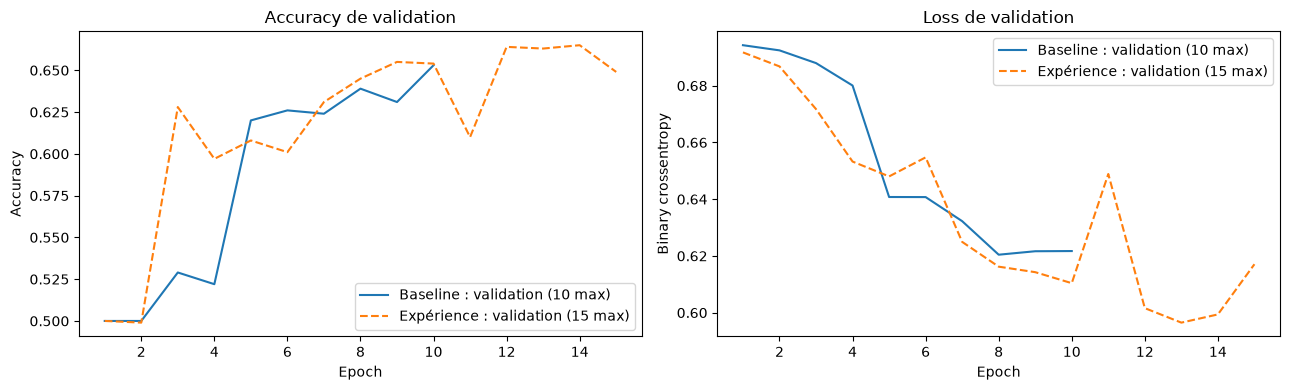

Baseline   | meilleure val_accuracy : 0.653 | meilleure val_loss : 0.620
15 epochs | meilleure val_accuracy : 0.665 | meilleure val_loss : 0.596
Gain d'accuracy : +1.2 point(s)


In [25]:
baseline_epochs_axis = range(1, len(history.history["accuracy"]) + 1)
experiment_epochs_axis = range(1, len(history_15.history["accuracy"]) + 1)

figure, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    baseline_epochs_axis,
    history.history["val_accuracy"],
    label="Baseline : validation (10 max)",
)
axes[0].plot(
    experiment_epochs_axis,
    history_15.history["val_accuracy"],
    "--",
    label="Expérience : validation (15 max)",
)
axes[0].set_title("Accuracy de validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    baseline_epochs_axis,
    history.history["val_loss"],
    label="Baseline : validation (10 max)",
)
axes[1].plot(
    experiment_epochs_axis,
    history_15.history["val_loss"],
    "--",
    label="Expérience : validation (15 max)",
)
axes[1].set_title("Loss de validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary crossentropy")
axes[1].legend()

plt.tight_layout()
plt.show()

baseline_best_accuracy = max(history.history["val_accuracy"])
experiment_best_accuracy = max(history_15.history["val_accuracy"])
baseline_best_loss = min(history.history["val_loss"])
experiment_best_loss = min(history_15.history["val_loss"])

print(f"Baseline   | meilleure val_accuracy : {baseline_best_accuracy:.3f} | meilleure val_loss : {baseline_best_loss:.3f}")
print(f"15 epochs | meilleure val_accuracy : {experiment_best_accuracy:.3f} | meilleure val_loss : {experiment_best_loss:.3f}")
print(f"Gain d'accuracy : {(experiment_best_accuracy - baseline_best_accuracy) * 100:+.1f} point(s)")


## 18. Expérience contrôlée sur la résolution

Nous cherchons maintenant un bon compromis entre performance et coût de calcul. Nous comparons `96 × 96`, `128 × 128` et `160 × 160`. L’architecture, le batch de 100, le taux d’apprentissage et les 10 epochs restent identiques. Le jeu de test final reste fermé.

Une image `96 × 96` contient 44 % de pixels de moins qu’une image `128 × 128`. Une image `160 × 160` en contient 56 % de plus. Le nombre de paramètres entraînables du CNN ne change pas grâce à la moyenne globale, mais les convolutions effectuent davantage de calculs quand l’image est plus grande.


In [2]:
BASELINE_SIZE = 128
RESOLUTIONS_TO_TRAIN = [96, 160]
RESOLUTION_EPOCHS = 10

baseline_pixels = BASELINE_SIZE ** 2
for resolution in [96, 128, 160]:
    relative_pixels = resolution ** 2 / baseline_pixels
    print(
        f"{resolution} × {resolution} : "
        f"{resolution ** 2:,} pixels, "
        f"soit {relative_pixels:.2f} × la charge spatiale de 128 × 128"
    )


96 × 96 : 9,216 pixels, soit 0.56 × la charge spatiale de 128 × 128
128 × 128 : 16,384 pixels, soit 1.00 × la charge spatiale de 128 × 128
160 × 160 : 25,600 pixels, soit 1.56 × la charge spatiale de 128 × 128


In [3]:
resolution_results = [
    {
        "resolution": BASELINE_SIZE,
        "best_val_accuracy": max(history.history["val_accuracy"]),
        "best_val_loss": min(history.history["val_loss"]),
        "training_seconds": training_seconds,
    }
]
resolution_histories = {
    BASELINE_SIZE: history.history,
}

for resolution in RESOLUTIONS_TO_TRAIN:
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    train_dataset_resolution = make_dataset(
        train_files,
        train_labels,
        resolution,
        BATCH_SIZE,
        should_shuffle=True,
    )
    validation_dataset_resolution = make_dataset(
        validation_files,
        validation_labels,
        resolution,
        BATCH_SIZE,
        should_shuffle=False,
    )

    resolution_model = build_cnn(resolution)
    resolution_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
    )

    start = time.perf_counter()
    resolution_history = resolution_model.fit(
        train_dataset_resolution,
        validation_data=validation_dataset_resolution,
        epochs=RESOLUTION_EPOCHS,
        shuffle=False,
        verbose=2,
    )
    duration = time.perf_counter() - start

    resolution_histories[resolution] = resolution_history.history
    resolution_results.append(
        {
            "resolution": resolution,
            "best_val_accuracy": max(
                resolution_history.history["val_accuracy"]
            ),
            "best_val_loss": min(
                resolution_history.history["val_loss"]
            ),
            "training_seconds": duration,
        }
    )

resolution_results = sorted(
    resolution_results,
    key=lambda result: result["resolution"],
)


Epoch 1/10


16/16 - 4s - 269ms/step - accuracy: 0.4750 - loss: 0.6947 - val_accuracy: 0.5000 - val_loss: 0.6918


Epoch 2/10


16/16 - 3s - 165ms/step - accuracy: 0.5006 - loss: 0.6911 - val_accuracy: 0.5000 - val_loss: 0.6859


Epoch 3/10


...

16/16 - 9s - 545ms/step - accuracy: 0.6225 - loss: 0.6423 - val_accuracy: 0.6400 - val_loss: 0.6213


Epoch 9/10


16/16 - 9s - 542ms/step - accuracy: 0.6294 - loss: 0.6311 - val_accuracy: 0.6340 - val_loss: 0.6186


Epoch 10/10


16/16 - 9s - 552ms/step - accuracy: 0.6419 - loss: 0.6282 - val_accuracy: 0.6230 - val_loss: 0.6259


### Résultats du compromis précision–calcul

Une résolution est intéressante si elle apporte une amélioration mesurable qui justifie son temps de calcul. Une différence minuscule d’accuracy accompagnée d’un temps beaucoup plus élevé ne constitue pas forcément un meilleur choix.


Résolution | meilleure val_accuracy | meilleure val_loss | temps
  96 × 96   | 0.655                 | 0.609              | 36.1 s
 128 × 128  | 0.653                 | 0.620              | 55.0 s
 160 × 160  | 0.640                 | 0.619              | 90.2 s


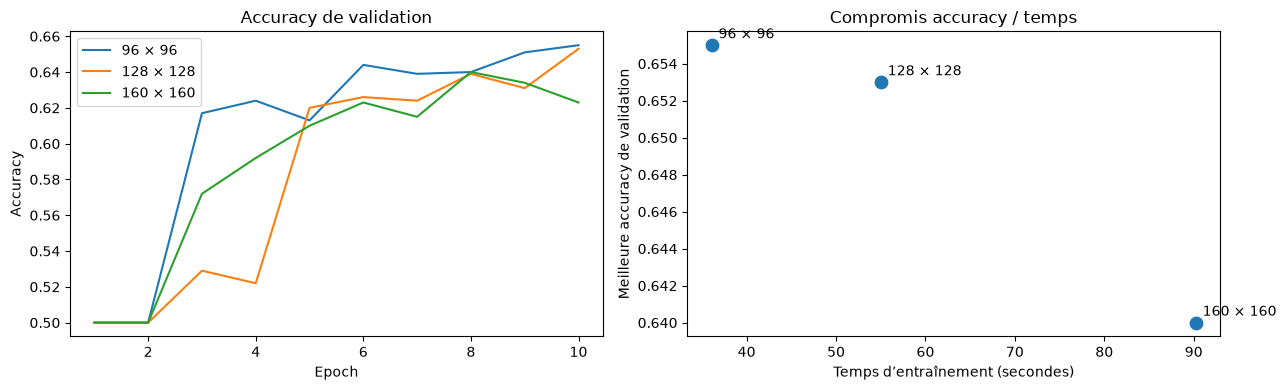

In [4]:
print("Résolution | meilleure val_accuracy | meilleure val_loss | temps")
for result in resolution_results:
    print(
        f"{result['resolution']:>4} × {result['resolution']:<4} | "
        f"{result['best_val_accuracy']:.3f}                 | "
        f"{result['best_val_loss']:.3f}              | "
        f"{result['training_seconds']:.1f} s"
    )

figure, axes = plt.subplots(1, 2, figsize=(13, 4))

for resolution in sorted(resolution_histories):
    values = resolution_histories[resolution]
    epoch_axis = range(1, len(values["val_accuracy"]) + 1)
    axes[0].plot(
        epoch_axis,
        values["val_accuracy"],
        label=f"{resolution} × {resolution}",
    )
axes[0].set_title("Accuracy de validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].scatter(
    [result["training_seconds"] for result in resolution_results],
    [result["best_val_accuracy"] for result in resolution_results],
    s=80,
)
for result in resolution_results:
    axes[1].annotate(
        f"{result['resolution']} × {result['resolution']}",
        (
            result["training_seconds"],
            result["best_val_accuracy"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
    )
axes[1].set_title("Compromis accuracy / temps")
axes[1].set_xlabel("Temps d’entraînement (secondes)")
axes[1].set_ylabel("Meilleure accuracy de validation")

plt.tight_layout()
plt.show()


## 19. Expérience contrôlée : augmentation des images

Nous conservons la résolution `96 × 96`, le même CNN, les mêmes données, le batch de 100, Adam à `0,001` et 10 epochs. Le seul changement est l’ajout de transformations aléatoires réalistes aux images d’entraînement.

Les couches d’augmentation s’activent uniquement pendant `fit`. Les images de validation restent toujours identiques. Aucun nouveau fichier n’est créé sur le disque et les labels ne changent pas.


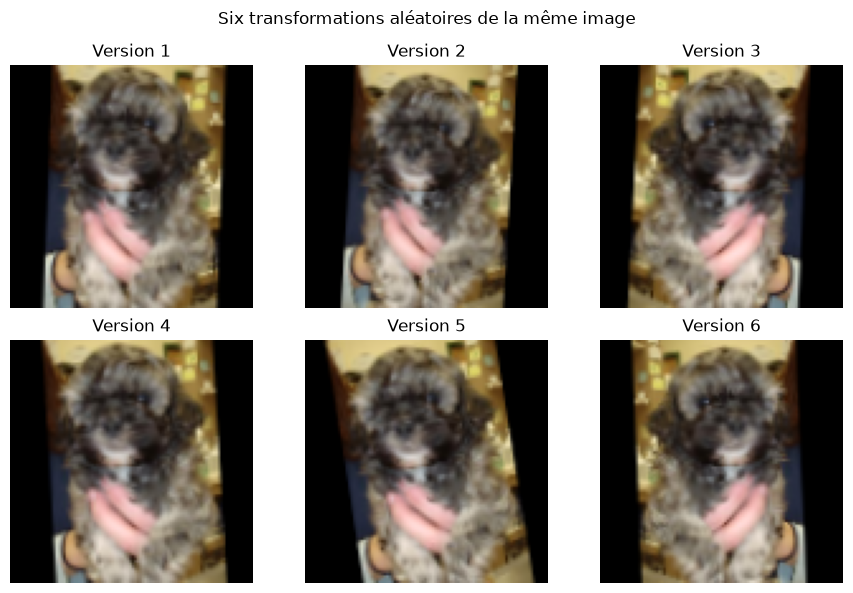

In [2]:
AUGMENTED_SIZE = 96

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal", seed=42),
        layers.RandomRotation(0.05, seed=43),
        layers.RandomZoom(0.10, seed=44),
        layers.RandomContrast(0.10, seed=45),
    ],
    name="data_augmentation",
)

sample_image = prepare_image(train_files[0], AUGMENTED_SIZE)
sample_batch = tf.repeat(sample_image[None, ...], repeats=6, axis=0)
augmented_samples = data_augmentation(sample_batch, training=True)

figure, axes = plt.subplots(2, 3, figsize=(9, 6))
for index, axis in enumerate(axes.flat):
    axis.imshow(tf.clip_by_value(augmented_samples[index], 0, 1))
    axis.set_title(f"Version {index + 1}")
    axis.axis("off")
plt.suptitle("Six transformations aléatoires de la même image")
plt.tight_layout()
plt.show()


### Placer l’augmentation devant le CNN

L’image transformée traverse ensuite exactement les quatre mêmes blocs convolution–pooling. Pendant la validation ou une future prédiction, Keras désactive automatiquement les transformations aléatoires.


In [3]:
def build_augmented_cnn(input_size):
    inputs = keras.Input(shape=(input_size, input_size, 3))
    x = data_augmentation(inputs)

    for block_number, number_of_filters in enumerate(
        [16, 32, 64, 128], start=1
    ):
        x = layers.Conv2D(
            filters=number_of_filters,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name=f"convolution_{block_number}",
        )(x)
        x = layers.MaxPooling2D(
            pool_size=(2, 2),
            name=f"pooling_{block_number}",
        )(x)

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)
    x = layers.Dense(
        units=64,
        activation="relu",
        name="dense_features",
    )(x)
    outputs = layers.Dense(
        units=1,
        activation="sigmoid",
        name="prediction",
    )(x)

    return keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="cnn_chats_chiens_augmente",
    )


In [4]:
augmented_train_dataset = make_dataset(
    train_files,
    train_labels,
    AUGMENTED_SIZE,
    BATCH_SIZE,
    should_shuffle=True,
)
augmented_validation_dataset = make_dataset(
    validation_files,
    validation_labels,
    AUGMENTED_SIZE,
    BATCH_SIZE,
    should_shuffle=False,
)

keras.backend.clear_session()
keras.utils.set_random_seed(42)
augmented_model = build_augmented_cnn(AUGMENTED_SIZE)
augmented_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

augmentation_start = time.perf_counter()
augmentation_history = augmented_model.fit(
    augmented_train_dataset,
    validation_data=augmented_validation_dataset,
    epochs=10,
    shuffle=False,
    verbose=2,
)
augmentation_seconds = time.perf_counter() - augmentation_start


Epoch 1/10


16/16 - 4s - 267ms/step - accuracy: 0.5056 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6938


Epoch 2/10


16/16 - 3s - 169ms/step - accuracy: 0.5000 - loss: 0.6935 - val_accuracy: 0.5000 - val_loss: 0.6927


Epoch 3/10


...

16/16 - 4s - 226ms/step - accuracy: 0.6044 - loss: 0.6645 - val_accuracy: 0.5720 - val_loss: 0.6801


Epoch 9/10


16/16 - 4s - 243ms/step - accuracy: 0.5788 - loss: 0.6679 - val_accuracy: 0.5790 - val_loss: 0.6744


Epoch 10/10


16/16 - 4s - 239ms/step - accuracy: 0.5600 - loss: 0.6740 - val_accuracy: 0.5890 - val_loss: 0.6589


### Comparer avec la baseline `96 × 96`

L’augmentation rend l’entraînement plus difficile : le modèle ne voit pas exactement les mêmes pixels à chaque epoch. Elle est utile seulement si cette difficulté supplémentaire améliore la généralisation sur les images de validation inchangées.


Sans augmentation | val_accuracy : 0.655 | val_loss : 0.609 | temps : 36.1 s
Avec augmentation | val_accuracy : 0.589 | val_loss : 0.659 | temps : 35.7 s
Différence d'accuracy : -6.6 point(s)


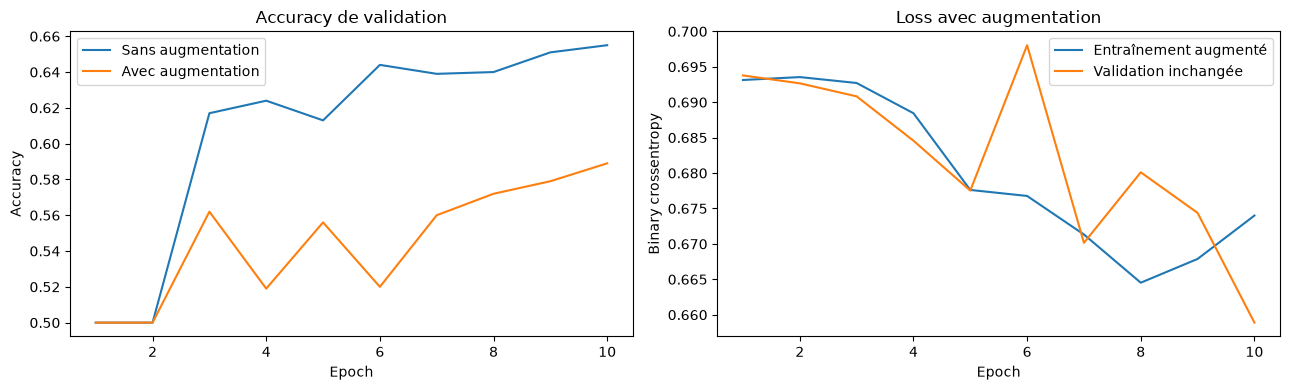

In [5]:
baseline_96_history = resolution_histories[96]

baseline_96_accuracy = max(baseline_96_history["val_accuracy"])
baseline_96_loss = min(baseline_96_history["val_loss"])
augmented_accuracy = max(augmentation_history.history["val_accuracy"])
augmented_loss = min(augmentation_history.history["val_loss"])

baseline_96_time = next(
    result["training_seconds"]
    for result in resolution_results
    if result["resolution"] == 96
)

print(
    f"Sans augmentation | val_accuracy : {baseline_96_accuracy:.3f} | "
    f"val_loss : {baseline_96_loss:.3f} | temps : {baseline_96_time:.1f} s"
)
print(
    f"Avec augmentation | val_accuracy : {augmented_accuracy:.3f} | "
    f"val_loss : {augmented_loss:.3f} | temps : {augmentation_seconds:.1f} s"
)
print(
    f"Différence d'accuracy : "
    f"{(augmented_accuracy - baseline_96_accuracy) * 100:+.1f} point(s)"
)

epoch_axis = range(1, 11)
figure, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    epoch_axis,
    baseline_96_history["val_accuracy"],
    label="Sans augmentation",
)
axes[0].plot(
    epoch_axis,
    augmentation_history.history["val_accuracy"],
    label="Avec augmentation",
)
axes[0].set_title("Accuracy de validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    epoch_axis,
    augmentation_history.history["loss"],
    label="Entraînement augmenté",
)
axes[1].plot(
    epoch_axis,
    augmentation_history.history["val_loss"],
    label="Validation inchangée",
)
axes[1].set_title("Loss avec augmentation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary crossentropy")
axes[1].legend()

plt.tight_layout()
plt.show()


## 20. Augmentation légère : retournement horizontal seulement

La première augmentation a rendu l’apprentissage trop difficile. Nous testons maintenant une seule transformation, réaliste et moins forte : retourner aléatoirement une image de gauche à droite. Tous les autres réglages restent identiques à la baseline `96 × 96`.


In [2]:
light_augmentation = keras.Sequential(
    [layers.RandomFlip("horizontal", seed=42)],
    name="light_augmentation",
)

def build_light_augmented_cnn(input_size):
    inputs = keras.Input(shape=(input_size, input_size, 3))
    x = light_augmentation(inputs)

    for block_number, number_of_filters in enumerate(
        [16, 32, 64, 128], start=1
    ):
        x = layers.Conv2D(
            filters=number_of_filters,
            kernel_size=(3, 3),
            padding="same",
            activation="relu",
            name=f"convolution_{block_number}",
        )(x)
        x = layers.MaxPooling2D(
            pool_size=(2, 2),
            name=f"pooling_{block_number}",
        )(x)

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)
    x = layers.Dense(
        units=64,
        activation="relu",
        name="dense_features",
    )(x)
    outputs = layers.Dense(
        units=1,
        activation="sigmoid",
        name="prediction",
    )(x)
    return keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="cnn_augmentation_legere",
    )


In [3]:
light_train_dataset = make_dataset(
    train_files,
    train_labels,
    96,
    BATCH_SIZE,
    should_shuffle=True,
)
light_validation_dataset = make_dataset(
    validation_files,
    validation_labels,
    96,
    BATCH_SIZE,
    should_shuffle=False,
)

keras.backend.clear_session()
keras.utils.set_random_seed(42)
light_augmented_model = build_light_augmented_cnn(96)
light_augmented_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

light_start = time.perf_counter()
light_augmentation_history = light_augmented_model.fit(
    light_train_dataset,
    validation_data=light_validation_dataset,
    epochs=10,
    shuffle=False,
    verbose=2,
)
light_augmentation_seconds = time.perf_counter() - light_start


Epoch 1/10


16/16 - 4s - 279ms/step - accuracy: 0.5156 - loss: 0.6919 - val_accuracy: 0.5000 - val_loss: 0.6947


Epoch 2/10


16/16 - 2s - 148ms/step - accuracy: 0.5000 - loss: 0.6942 - val_accuracy: 0.5000 - val_loss: 0.6930


Epoch 3/10


...

16/16 - 3s - 201ms/step - accuracy: 0.6256 - loss: 0.6410 - val_accuracy: 0.6430 - val_loss: 0.6229


Epoch 9/10


16/16 - 3s - 200ms/step - accuracy: 0.6331 - loss: 0.6393 - val_accuracy: 0.6230 - val_loss: 0.6291


Epoch 10/10


16/16 - 3s - 200ms/step - accuracy: 0.6137 - loss: 0.6433 - val_accuracy: 0.6500 - val_loss: 0.6268


### Comparer les trois configurations

Nous comparons la baseline sans augmentation, l’augmentation forte et le retournement horizontal seul. Cette comparaison permet de distinguer l’effet du principe d’augmentation de celui de transformations trop fortes.


Sans augmentation  | accuracy : 0.655 | loss : 0.609 | temps : 36.1 s
Augmentation forte | accuracy : 0.589 | loss : 0.659 | temps : 35.7 s
Flip horizontal    | accuracy : 0.650 | loss : 0.623 | temps : 31.3 s


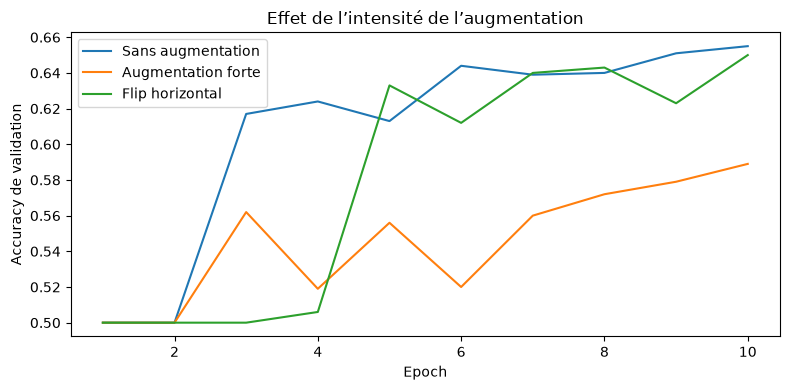

In [4]:
light_accuracy = max(
    light_augmentation_history.history["val_accuracy"]
)
light_loss = min(
    light_augmentation_history.history["val_loss"]
)

print(
    f"Sans augmentation  | accuracy : {baseline_96_accuracy:.3f} | "
    f"loss : {baseline_96_loss:.3f} | temps : {baseline_96_time:.1f} s"
)
print(
    f"Augmentation forte | accuracy : {augmented_accuracy:.3f} | "
    f"loss : {augmented_loss:.3f} | temps : {augmentation_seconds:.1f} s"
)
print(
    f"Flip horizontal    | accuracy : {light_accuracy:.3f} | "
    f"loss : {light_loss:.3f} | temps : {light_augmentation_seconds:.1f} s"
)

epoch_axis = range(1, 11)
plt.figure(figsize=(8, 4))
plt.plot(
    epoch_axis,
    baseline_96_history["val_accuracy"],
    label="Sans augmentation",
)
plt.plot(
    epoch_axis,
    augmentation_history.history["val_accuracy"],
    label="Augmentation forte",
)
plt.plot(
    epoch_axis,
    light_augmentation_history.history["val_accuracy"],
    label="Flip horizontal",
)
plt.title("Effet de l’intensité de l’augmentation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy de validation")
plt.legend()
plt.tight_layout()
plt.show()


## 21. Batch Normalization et Dropout

Nous conservons la baseline `96 × 96` sans augmentation. Après chaque convolution, `BatchNormalization` stabilise l’échelle des activations avant ReLU. Après la couche Dense de 64 neurones, `Dropout(0.20)` masque aléatoirement 20 % des activations pendant l’entraînement seulement. Les autres réglages restent identiques.

Cette expérience regroupe les deux techniques demandées par le sujet. Elle mesure donc leur effet combiné ; elle ne permet pas d’attribuer un éventuel gain à une seule des deux.


In [2]:
def build_batchnorm_dropout_cnn(input_size):
    inputs = keras.Input(shape=(input_size, input_size, 3))
    x = inputs

    for block_number, number_of_filters in enumerate(
        [16, 32, 64, 128], start=1
    ):
        x = layers.Conv2D(
            filters=number_of_filters,
            kernel_size=(3, 3),
            padding="same",
            use_bias=False,
            name=f"convolution_{block_number}",
        )(x)
        x = layers.BatchNormalization(
            name=f"batch_normalization_{block_number}"
        )(x)
        x = layers.Activation(
            "relu",
            name=f"relu_{block_number}",
        )(x)
        x = layers.MaxPooling2D(
            pool_size=(2, 2),
            name=f"pooling_{block_number}",
        )(x)

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)
    x = layers.Dense(
        units=64,
        activation="relu",
        name="dense_features",
    )(x)
    x = layers.Dropout(
        rate=0.20,
        seed=42,
        name="dropout",
    )(x)
    outputs = layers.Dense(
        units=1,
        activation="sigmoid",
        name="prediction",
    )(x)

    return keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="cnn_batchnorm_dropout",
    )


In [3]:
regularized_train_dataset = make_dataset(
    train_files,
    train_labels,
    96,
    BATCH_SIZE,
    should_shuffle=True,
)
regularized_validation_dataset = make_dataset(
    validation_files,
    validation_labels,
    96,
    BATCH_SIZE,
    should_shuffle=False,
)

keras.backend.clear_session()
keras.utils.set_random_seed(42)
regularized_model = build_batchnorm_dropout_cnn(96)
regularized_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

regularized_start = time.perf_counter()
regularized_history = regularized_model.fit(
    regularized_train_dataset,
    validation_data=regularized_validation_dataset,
    epochs=10,
    shuffle=False,
    verbose=2,
)
regularized_seconds = time.perf_counter() - regularized_start


Epoch 1/10


16/16 - 7s - 452ms/step - accuracy: 0.5638 - loss: 0.7155 - val_accuracy: 0.5000 - val_loss: 0.6937


Epoch 2/10


16/16 - 6s - 352ms/step - accuracy: 0.6356 - loss: 0.6381 - val_accuracy: 0.5000 - val_loss: 0.7039


Epoch 3/10


...

16/16 - 7s - 413ms/step - accuracy: 0.7675 - loss: 0.4829 - val_accuracy: 0.5000 - val_loss: 0.7370


Epoch 9/10


16/16 - 6s - 399ms/step - accuracy: 0.7862 - loss: 0.4662 - val_accuracy: 0.5000 - val_loss: 0.8758


Epoch 10/10


16/16 - 6s - 397ms/step - accuracy: 0.8031 - loss: 0.4319 - val_accuracy: 0.5000 - val_loss: 0.9038


### Comparer à la baseline sélectionnée

Nous cherchons une amélioration sur les images de validation inchangées. Le jeu de test final reste fermé.


Baseline 96 × 96       | accuracy : 0.655 | loss : 0.609 | temps : 36.1 s
BatchNorm + Dropout    | accuracy : 0.504 | loss : 0.694 | temps : 64.6 s
Différence d'accuracy : -15.1 point(s)


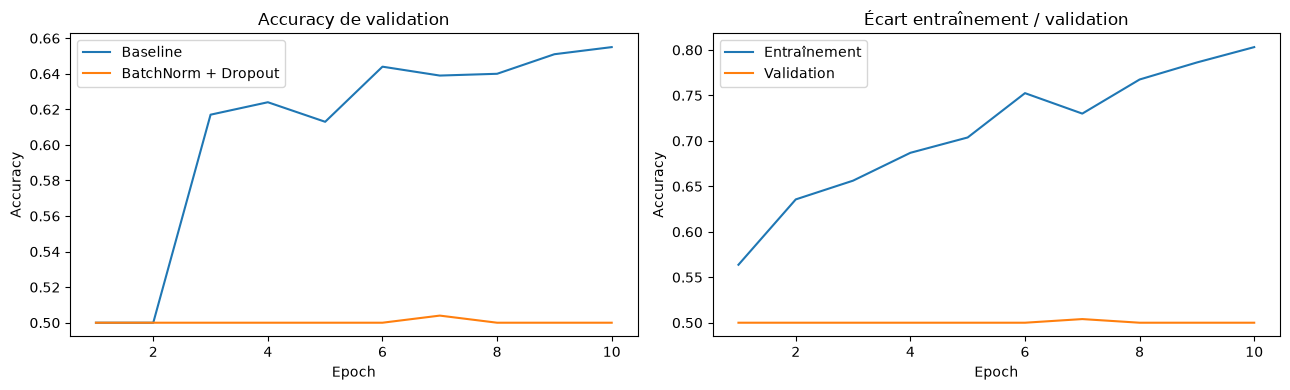

In [4]:
regularized_accuracy = max(
    regularized_history.history["val_accuracy"]
)
regularized_loss = min(
    regularized_history.history["val_loss"]
)

print(
    f"Baseline 96 × 96       | accuracy : {baseline_96_accuracy:.3f} | "
    f"loss : {baseline_96_loss:.3f} | temps : {baseline_96_time:.1f} s"
)
print(
    f"BatchNorm + Dropout    | accuracy : {regularized_accuracy:.3f} | "
    f"loss : {regularized_loss:.3f} | temps : {regularized_seconds:.1f} s"
)
print(
    f"Différence d'accuracy : "
    f"{(regularized_accuracy - baseline_96_accuracy) * 100:+.1f} point(s)"
)

epoch_axis = range(1, 11)
figure, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(
    epoch_axis,
    baseline_96_history["val_accuracy"],
    label="Baseline",
)
axes[0].plot(
    epoch_axis,
    regularized_history.history["val_accuracy"],
    label="BatchNorm + Dropout",
)
axes[0].set_title("Accuracy de validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    epoch_axis,
    regularized_history.history["accuracy"],
    label="Entraînement",
)
axes[1].plot(
    epoch_axis,
    regularized_history.history["val_accuracy"],
    label="Validation",
)
axes[1].set_title("Écart entraînement / validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


## 22. Bonus : transfer learning avec MobileNetV2

Notre CNN précédent devait apprendre tous ses filtres à partir de 1 600 images. MobileNetV2 possède déjà des filtres appris sur ImageNet. Nous retirons son ancien classifieur (`include_top=False`), gelons sa base convolutionnelle, puis ajoutons un seul neurone sigmoid pour notre problème chat/chien.

Les datasets produisent des pixels entre `0` et `1`. MobileNetV2 attend des pixels entre `-1` et `1`, donc `Rescaling(2, offset=-1)` effectue la conversion. Nous gardons la résolution efficace `96 × 96`, sans augmentation.


In [2]:
TRANSFER_SIZE = 96

mobilenet_base = keras.applications.MobileNetV2(
    input_shape=(TRANSFER_SIZE, TRANSFER_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
mobilenet_base.trainable = False

transfer_inputs = keras.Input(
    shape=(TRANSFER_SIZE, TRANSFER_SIZE, 3)
)
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0,
    name="mobilenet_preprocessing",
)(transfer_inputs)
x = mobilenet_base(x, training=False)
x = layers.GlobalAveragePooling2D(
    name="transfer_global_average_pooling"
)(x)
transfer_outputs = layers.Dense(
    units=1,
    activation="sigmoid",
    name="transfer_prediction",
)(x)

transfer_model = keras.Model(
    inputs=transfer_inputs,
    outputs=transfer_outputs,
    name="mobilenetv2_chats_chiens",
)

trainable_parameters = sum(
    int(np.prod(weight.shape))
    for weight in transfer_model.trainable_weights
)
frozen_parameters = sum(
    int(np.prod(weight.shape))
    for weight in transfer_model.non_trainable_weights
)

print("Paramètres entraînables :", trainable_parameters)
print("Paramètres gelés :", frozen_parameters)


      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  49152/9406464 ━━━━━━━━━━━━━━━━━━━━ 18s 2us/step

  81920/9406464 ━━━━━━━━━━━━━━━━━━━━ 21s 2us/step

 147456/9406464 ━━━━━━━━━━━━━━━━━━━━ 14s 2us/step

 245760/9406464 ━━━━━━━━━━━━━━━━━━━━ 10s 1us/step

...

8364032/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

9232384/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Paramètres entraînables :

 1281
Paramètres gelés : 2257984


### Entraîner seulement le nouveau classifieur

`mobilenet_base.trainable = False` empêche la modification des filtres pré-entraînés. Avec la moyenne globale, MobileNetV2 produit 1 280 caractéristiques ; le neurone final apprend donc 1 280 poids et un biais, soit 1 281 paramètres entraînables.


In [3]:
transfer_train_dataset = make_dataset(
    train_files,
    train_labels,
    TRANSFER_SIZE,
    BATCH_SIZE,
    should_shuffle=True,
)
transfer_validation_dataset = make_dataset(
    validation_files,
    validation_labels,
    TRANSFER_SIZE,
    BATCH_SIZE,
    should_shuffle=False,
)

keras.utils.set_random_seed(42)
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

transfer_start = time.perf_counter()
transfer_history = transfer_model.fit(
    transfer_train_dataset,
    validation_data=transfer_validation_dataset,
    epochs=5,
    shuffle=False,
    verbose=2,
)
transfer_seconds = time.perf_counter() - transfer_start

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)
transfer_model.save(MODELS_DIR / "mobilenetv2_frozen.keras")


Epoch 1/5


16/16 - 9s - 566ms/step - accuracy: 0.7287 - loss: 0.5313 - val_accuracy: 0.8950 - val_loss: 0.3064


Epoch 2/5


16/16 - 5s - 343ms/step - accuracy: 0.9137 - loss: 0.2406 - val_accuracy: 0.9370 - val_loss: 0.1950


Epoch 3/5


16/16 - 6s - 360ms/step - accuracy: 0.9394 - loss: 0.1781 - val_accuracy: 0.9380 - val_loss: 0.1636


Epoch 4/5


16/16 - 6s - 371ms/step - accuracy: 0.9506 - loss: 0.1516 - val_accuracy: 0.9380 - val_loss: 0.1457


Epoch 5/5


16/16 - 6s - 383ms/step - accuracy: 0.9594 - loss: 0.1345 - val_accuracy: 0.9390 - val_loss: 0.1377


### Comparer le CNN créé de zéro et le modèle pré-entraîné

Le jeu de validation reste le seul outil de comparaison. Les 400 images de test restent fermées jusqu’à la sélection définitive.


CNN créé de zéro | accuracy : 0.655 | loss : 0.609 | temps : 36.1 s
MobileNetV2 gelé | accuracy : 0.939 | loss : 0.138 | temps : 32.4 s
Gain d'accuracy : +28.4 point(s)


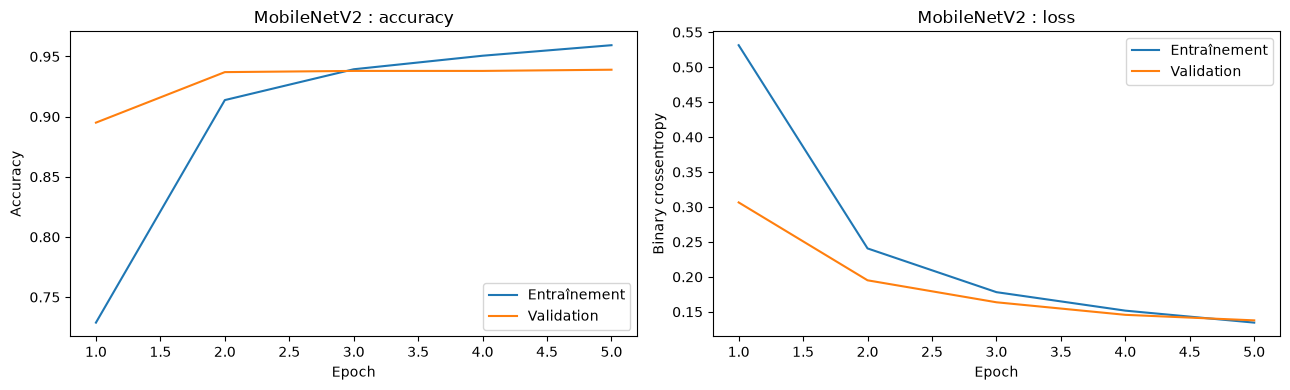

In [4]:
transfer_accuracy = max(
    transfer_history.history["val_accuracy"]
)
transfer_loss = min(
    transfer_history.history["val_loss"]
)

print(
    f"CNN créé de zéro | accuracy : {baseline_96_accuracy:.3f} | "
    f"loss : {baseline_96_loss:.3f} | temps : {baseline_96_time:.1f} s"
)
print(
    f"MobileNetV2 gelé | accuracy : {transfer_accuracy:.3f} | "
    f"loss : {transfer_loss:.3f} | temps : {transfer_seconds:.1f} s"
)
print(
    f"Gain d'accuracy : "
    f"{(transfer_accuracy - baseline_96_accuracy) * 100:+.1f} point(s)"
)

transfer_epoch_axis = range(1, 6)
figure, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(
    transfer_epoch_axis,
    transfer_history.history["accuracy"],
    label="Entraînement",
)
axes[0].plot(
    transfer_epoch_axis,
    transfer_history.history["val_accuracy"],
    label="Validation",
)
axes[0].set_title("MobileNetV2 : accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    transfer_epoch_axis,
    transfer_history.history["loss"],
    label="Entraînement",
)
axes[1].plot(
    transfer_epoch_axis,
    transfer_history.history["val_loss"],
    label="Validation",
)
axes[1].set_title("MobileNetV2 : loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary crossentropy")
axes[1].legend()

plt.tight_layout()
plt.show()


## 23. Évaluation finale sur les 400 images de test

MobileNetV2 a été sélectionné grâce à la validation. Nous ouvrons maintenant le jeu de test, une seule fois, sans modifier le modèle. Une probabilité inférieure à `0,5` donne `chat` et une probabilité supérieure ou égale à `0,5` donne `chien`.


In [2]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

final_model = keras.models.load_model(
    PROJECT_DIR / "models" / "mobilenetv2_frozen.keras"
)
final_test_dataset = make_dataset(
    test_files,
    test_labels,
    96,
    BATCH_SIZE,
    should_shuffle=False,
)

test_probabilities = final_model.predict(
    final_test_dataset,
    verbose=0,
).reshape(-1)
test_predictions = (test_probabilities >= 0.5).astype(int)
test_labels_array = np.asarray(test_labels)

test_accuracy = accuracy_score(
    test_labels_array,
    test_predictions,
)
test_precision = precision_score(
    test_labels_array,
    test_predictions,
    zero_division=0,
)
test_recall = recall_score(
    test_labels_array,
    test_predictions,
    zero_division=0,
)
test_f1 = f1_score(
    test_labels_array,
    test_predictions,
    zero_division=0,
)
test_confusion = confusion_matrix(
    test_labels_array,
    test_predictions,
)

print(f"Accuracy  : {test_accuracy:.3f}")
print(f"Précision : {test_precision:.3f}")
print(f"Rappel    : {test_recall:.3f}")
print(f"F1-score  : {test_f1:.3f}")
print("Matrice de confusion :")
print(test_confusion)


Accuracy  : 0.943
Précision : 0.945
Rappel    : 0.940
F1-score  : 0.942
Matrice de confusion :
[[189  11]
 [ 12 188]]


### Lire la matrice de confusion

Les lignes correspondent aux vraies classes et les colonnes aux prédictions. Avec `chat = 0` et `chien = 1`, la matrice contient dans l’ordre : vrais chats, chats pris pour des chiens, chiens pris pour des chats, vrais chiens.


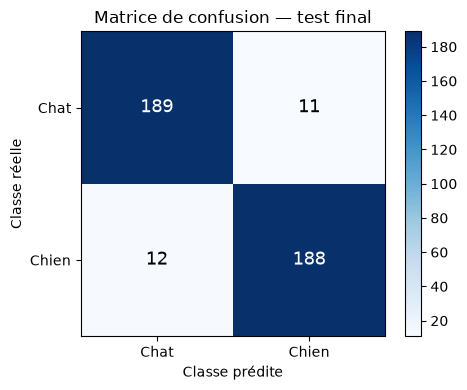

Chats correctement reconnus : 189
Chats pris pour des chiens   : 11
Chiens pris pour des chats   : 12
Chiens correctement reconnus : 188


In [3]:
true_cats, cats_predicted_as_dogs = test_confusion[0]
dogs_predicted_as_cats, true_dogs = test_confusion[1]

figure, axis = plt.subplots(figsize=(5, 4))
image = axis.imshow(test_confusion, cmap="Blues")
axis.set_xticks([0, 1], labels=["Chat", "Chien"])
axis.set_yticks([0, 1], labels=["Chat", "Chien"])
axis.set_xlabel("Classe prédite")
axis.set_ylabel("Classe réelle")
axis.set_title("Matrice de confusion — test final")

for row in range(2):
    for column in range(2):
        axis.text(
            column,
            row,
            test_confusion[row, column],
            ha="center",
            va="center",
            color="white" if test_confusion[row, column] > 100 else "black",
            fontsize=13,
        )

figure.colorbar(image, ax=axis)
plt.tight_layout()
plt.show()

print("Chats correctement reconnus :", true_cats)
print("Chats pris pour des chiens   :", cats_predicted_as_dogs)
print("Chiens pris pour des chats   :", dogs_predicted_as_cats)
print("Chiens correctement reconnus :", true_dogs)


## 24. Prolonger proprement MobileNetV2 avec EarlyStopping

Les courbes du premier MobileNetV2 progressaient encore à la cinquième epoch. Nous reconstruisons donc la même architecture avec une seed fixée avant sa création, un maximum de 15 epochs et un arrêt automatique. `restore_best_weights=True` conserve les poids associés à la plus petite loss de validation.

Cette expérience est réalisée après l’ouverture du test final. Elle reste donc une exploration supplémentaire comparée uniquement sur la validation ; elle ne remplace pas le score final impartial de `94,3 %`.


In [2]:
keras.backend.clear_session()
keras.utils.set_random_seed(42)

extended_base = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet",
)
extended_base.trainable = False

extended_inputs = keras.Input(shape=(96, 96, 3))
x = layers.Rescaling(2.0, offset=-1.0)(extended_inputs)
x = extended_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
extended_outputs = layers.Dense(1, activation="sigmoid")(x)

extended_model = keras.Model(
    extended_inputs,
    extended_outputs,
    name="mobilenetv2_extended",
)
extended_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

extended_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    min_delta=0.001,
    restore_best_weights=True,
)
extended_checkpoint_path = (
    PROJECT_DIR / "models" / "mobilenetv2_frozen_best.keras"
)
extended_checkpoint = keras.callbacks.ModelCheckpoint(
    extended_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
)


In [3]:
extended_train_dataset = make_dataset(
    train_files,
    train_labels,
    96,
    BATCH_SIZE,
    should_shuffle=True,
)
extended_validation_dataset = make_dataset(
    validation_files,
    validation_labels,
    96,
    BATCH_SIZE,
    should_shuffle=False,
)

extended_start = time.perf_counter()
extended_history = extended_model.fit(
    extended_train_dataset,
    validation_data=extended_validation_dataset,
    epochs=15,
    callbacks=[extended_early_stopping, extended_checkpoint],
    shuffle=False,
    verbose=2,
)
extended_seconds = time.perf_counter() - extended_start

extended_epochs = len(extended_history.history["loss"])
extended_best_index = int(
    np.argmin(extended_history.history["val_loss"])
)
extended_best_epoch = extended_best_index + 1
extended_best_accuracy = extended_history.history["val_accuracy"][
    extended_best_index
]
extended_best_loss = extended_history.history["val_loss"][
    extended_best_index
]

print("Epochs effectuées :", extended_epochs)
print("Meilleure epoch selon val_loss :", extended_best_epoch)
print(f"Accuracy à cette epoch : {extended_best_accuracy:.3f}")
print(f"Loss à cette epoch : {extended_best_loss:.3f}")
print(f"Temps total : {extended_seconds:.1f} s")


Epoch 1/15


16/16 - 13s - 826ms/step - accuracy: 0.7219 - loss: 0.5476 - val_accuracy: 0.8750 - val_loss: 0.3215


Epoch 2/15


16/16 - 8s - 477ms/step - accuracy: 0.9156 - loss: 0.2448 - val_accuracy: 0.9240 - val_loss: 0.2003


Epoch 3/15


...

Epoch 14/15


16/16 - 8s - 489ms/step - accuracy: 0.9837 - loss: 0.0707 - val_accuracy: 0.9510 - val_loss: 0.1184


Epoch 15/15


16/16 - 8s - 497ms/step - accuracy: 0.9862 - loss: 0.0670 - val_accuracy: 0.9510 - val_loss: 0.1178


Epochs effectuées : 15
Meilleure epoch selon val_loss : 15
Accuracy à cette epoch : 0.951
Loss à cette epoch : 0.118
Temps total : 133.8 s


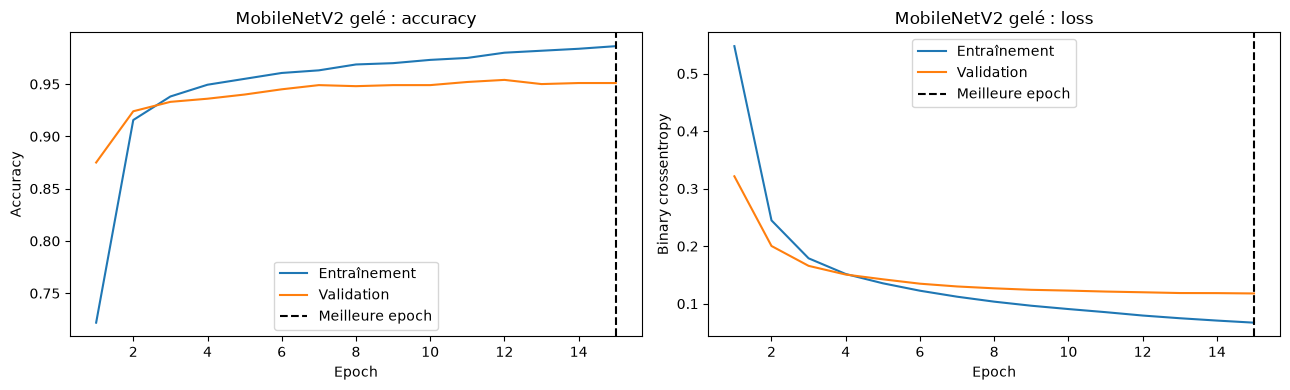

In [4]:
extended_axis = range(1, extended_epochs + 1)
figure, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(
    extended_axis,
    extended_history.history["accuracy"],
    label="Entraînement",
)
axes[0].plot(
    extended_axis,
    extended_history.history["val_accuracy"],
    label="Validation",
)
axes[0].axvline(
    extended_best_epoch,
    color="black",
    linestyle="--",
    label="Meilleure epoch",
)
axes[0].set_title("MobileNetV2 gelé : accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    extended_axis,
    extended_history.history["loss"],
    label="Entraînement",
)
axes[1].plot(
    extended_axis,
    extended_history.history["val_loss"],
    label="Validation",
)
axes[1].axvline(
    extended_best_epoch,
    color="black",
    linestyle="--",
    label="Meilleure epoch",
)
axes[1].set_title("MobileNetV2 gelé : loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary crossentropy")
axes[1].legend()

plt.tight_layout()
figure.savefig(
    PROJECT_DIR / 'artifacts' / 'mobilenetv2_extended_training.png',
    dpi=160,
    bbox_inches='tight',
)
plt.show()


## 25. Fine-tuning : adapter la fin de MobileNetV2

Le modèle précédent utilisait MobileNetV2 comme un lecteur d'images **figé** : ses poids ImageNet étaient utilisés, mais jamais modifiés. Ici, nous dégelons seulement les 20 dernières couches du lecteur.

- les premières couches restent figées : elles savent déjà détecter des éléments généraux comme les contours et les textures ;
- les dernières couches peuvent s'adapter légèrement à notre problème chats/chiens ;
- le learning rate est réduit de `0.001` à `0.00001` afin de modifier doucement les bons poids déjà appris ;
- les couches de Batch Normalization restent figées et MobileNetV2 continue d'être appelé avec `training=False`.

Après avoir changé les couches entraînables, il faut obligatoirement recompiler le modèle. Le choix final repose encore sur la loss de validation, jamais sur le test final.


In [2]:
fine_tune_model = keras.models.load_model(
    PROJECT_DIR / "models" / "mobilenetv2_frozen_best.keras"
)
fine_tune_base = fine_tune_model.get_layer("mobilenetv2_1.00_96")

# On ouvre seulement la fin du modèle pré-entraîné.
fine_tune_base.trainable = True
fine_tune_at = len(fine_tune_base.layers) - 20

for layer_index, layer in enumerate(fine_tune_base.layers):
    should_train = layer_index >= fine_tune_at
    if isinstance(layer, layers.BatchNormalization):
        should_train = False
    layer.trainable = should_train

# Changer trainable nécessite une nouvelle compilation.
fine_tune_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

fine_tune_trainable = sum(
    int(np.prod(variable.shape))
    for variable in fine_tune_model.trainable_weights
)
fine_tune_frozen = sum(
    int(np.prod(variable.shape))
    for variable in fine_tune_model.non_trainable_weights
)

print("Couches de MobileNetV2 :", len(fine_tune_base.layers))
print("Point de dégel : couche", fine_tune_at)
print("Paramètres désormais entraînables :", fine_tune_trainable)
print("Paramètres encore figés :", fine_tune_frozen)

fine_tune_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    min_delta=0.001,
    restore_best_weights=True,
)
fine_tune_checkpoint_path = (
    PROJECT_DIR / "models" / "mobilenetv2_finetuned_best.keras"
)
fine_tune_checkpoint = keras.callbacks.ModelCheckpoint(
    fine_tune_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
)


Couches de MobileNetV2 : 154
Point de dégel : couche 134
Paramètres désormais entraînables : 1196161
Paramètres encore figés : 1063104


In [3]:
fine_tune_train_dataset = make_dataset(
    train_files,
    train_labels,
    96,
    BATCH_SIZE,
    should_shuffle=True,
)
fine_tune_validation_dataset = make_dataset(
    validation_files,
    validation_labels,
    96,
    BATCH_SIZE,
    should_shuffle=False,
)

fine_tune_start = time.perf_counter()
fine_tune_history = fine_tune_model.fit(
    fine_tune_train_dataset,
    validation_data=fine_tune_validation_dataset,
    epochs=10,
    callbacks=[fine_tune_early_stopping, fine_tune_checkpoint],
    shuffle=False,
    verbose=2,
)
fine_tune_seconds = time.perf_counter() - fine_tune_start

fine_tune_epochs = len(fine_tune_history.history["loss"])
fine_tune_best_index = int(
    np.argmin(fine_tune_history.history["val_loss"])
)
fine_tune_best_epoch = fine_tune_best_index + 1
fine_tune_best_accuracy = fine_tune_history.history["val_accuracy"][
    fine_tune_best_index
]
fine_tune_best_loss = fine_tune_history.history["val_loss"][
    fine_tune_best_index
]

print("Epochs effectuées :", fine_tune_epochs)
print("Meilleure epoch selon val_loss :", fine_tune_best_epoch)
print(f"Accuracy à cette epoch : {fine_tune_best_accuracy:.3f}")
print(f"Loss à cette epoch : {fine_tune_best_loss:.3f}")
print(f"Temps total : {fine_tune_seconds:.1f} s")


Epoch 1/10


16/16 - 15s - 950ms/step - accuracy: 0.9831 - loss: 0.0654 - val_accuracy: 0.9580 - val_loss: 0.1158


Epoch 2/10


16/16 - 6s - 384ms/step - accuracy: 0.9894 - loss: 0.0481 - val_accuracy: 0.9460 - val_loss: 0.1208


Epoch 3/10


...

Epoch 4/10


16/16 - 7s - 431ms/step - accuracy: 0.9975 - loss: 0.0310 - val_accuracy: 0.9560 - val_loss: 0.1115


Epoch 5/10


16/16 - 7s - 416ms/step - accuracy: 0.9981 - loss: 0.0249 - val_accuracy: 0.9490 - val_loss: 0.1143


Epochs effectuées : 5
Meilleure epoch selon val_loss : 4
Accuracy à cette epoch : 0.956
Loss à cette epoch : 0.112
Temps total : 41.7 s


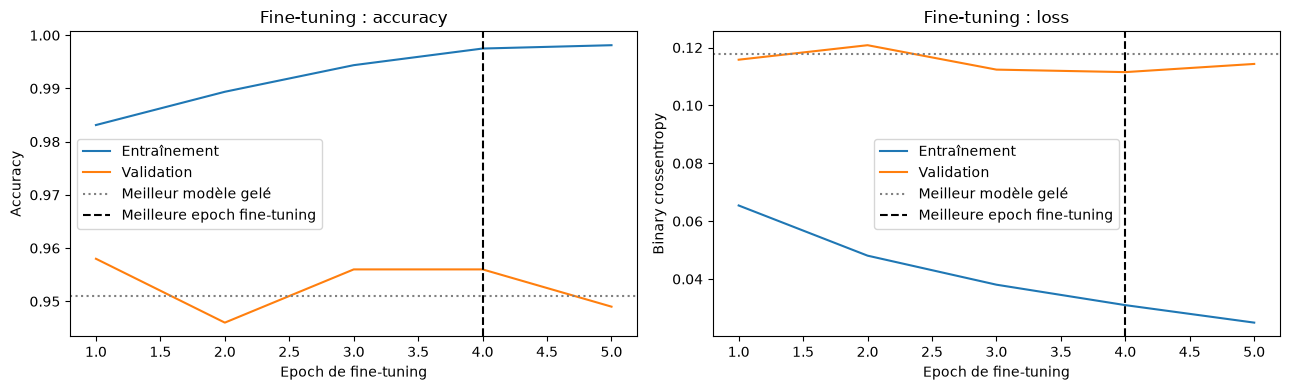

Comparaison sur la validation
Gelé       : accuracy=0.951, loss=0.118
Fine-tuné  : accuracy=0.956, loss=0.112


In [4]:
fine_tune_axis = range(1, fine_tune_epochs + 1)
figure, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    fine_tune_axis,
    fine_tune_history.history["accuracy"],
    label="Entraînement",
)
axes[0].plot(
    fine_tune_axis,
    fine_tune_history.history["val_accuracy"],
    label="Validation",
)
axes[0].axhline(
    extended_best_accuracy,
    color="grey",
    linestyle=":",
    label="Meilleur modèle gelé",
)
axes[0].axvline(
    fine_tune_best_epoch,
    color="black",
    linestyle="--",
    label="Meilleure epoch fine-tuning",
)
axes[0].set_title("Fine-tuning : accuracy")
axes[0].set_xlabel("Epoch de fine-tuning")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    fine_tune_axis,
    fine_tune_history.history["loss"],
    label="Entraînement",
)
axes[1].plot(
    fine_tune_axis,
    fine_tune_history.history["val_loss"],
    label="Validation",
)
axes[1].axhline(
    extended_best_loss,
    color="grey",
    linestyle=":",
    label="Meilleur modèle gelé",
)
axes[1].axvline(
    fine_tune_best_epoch,
    color="black",
    linestyle="--",
    label="Meilleure epoch fine-tuning",
)
axes[1].set_title("Fine-tuning : loss")
axes[1].set_xlabel("Epoch de fine-tuning")
axes[1].set_ylabel("Binary crossentropy")
axes[1].legend()

plt.tight_layout()
figure.savefig(
    PROJECT_DIR / "artifacts" / "mobilenetv2_finetuning.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Comparaison sur la validation")
print(
    f"Gelé       : accuracy={extended_best_accuracy:.3f}, "
    f"loss={extended_best_loss:.3f}"
)
print(
    f"Fine-tuné  : accuracy={fine_tune_best_accuracy:.3f}, "
    f"loss={fine_tune_best_loss:.3f}"
)


### Conclusion du fine-tuning

Le fine-tuning améliore légèrement la validation : l'accuracy passe de **95,1 % à 95,6 %** et la loss de **0,118 à 0,112**. Le gain observé est donc petit, tandis que l'accuracy d'entraînement approche déjà 100 %. Continuer à entraîner risquerait surtout d'augmenter la mémorisation.

Le callback `EarlyStopping` ne cherche pas une « meilleure accuracy magique ». Il surveille ici `val_loss` : après deux epochs sans amélioration suffisante, il arrête l'entraînement et restaure les meilleurs poids observés. `ModelCheckpoint` conserve en plus le fichier correspondant à la loss de validation exactement la plus basse.

Cette expérience a été réalisée après l'ouverture du test final. Elle reste donc une analyse exploratoire comparée sur la validation ; le score de test honnête du projet demeure **94,3 %**, obtenu avec le modèle sélectionné avant l'ouverture du test.

## 26. MobileNetV2 : comparer 96 × 96 et 128 × 128

Le CNN construit à la main avait été plus efficace en `96 × 96`, mais ce résultat ne prouve pas que MobileNetV2 préfère aussi cette résolution. Nous entraînons donc une nouvelle tête de classification sur une base MobileNetV2 gelée en `128 × 128`.

Toutes les autres conditions restent identiques au test MobileNetV2 gelé en `96 × 96` : mêmes images, même découpage, batch de 100, Adam à `0.001`, maximum de 15 epochs et sélection selon la loss de validation. Cela permet d'étudier séparément l'effet de la résolution.


In [2]:
keras.backend.clear_session()
keras.utils.set_random_seed(42)

resolution_128_base = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet",
)
resolution_128_base.trainable = False

resolution_128_inputs = keras.Input(shape=(128, 128, 3))
x = layers.Rescaling(2.0, offset=-1.0)(resolution_128_inputs)
x = resolution_128_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
resolution_128_outputs = layers.Dense(1, activation="sigmoid")(x)

resolution_128_model = keras.Model(
    resolution_128_inputs,
    resolution_128_outputs,
    name="mobilenetv2_128_frozen",
)
resolution_128_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

resolution_128_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    min_delta=0.001,
    restore_best_weights=True,
)
resolution_128_checkpoint_path = (
    PROJECT_DIR / "models" / "mobilenetv2_128_frozen_best.keras"
)
resolution_128_checkpoint = keras.callbacks.ModelCheckpoint(
    resolution_128_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
)


      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  40960/9406464 ━━━━━━━━━━━━━━━━━━━━ 13s 1us/step

  98304/9406464 ━━━━━━━━━━━━━━━━━━━━ 10s 1us/step

 147456/9406464 ━━━━━━━━━━━━━━━━━━━━ 13s 1us/step

 262144/9406464 ━━━━━━━━━━━━━━━━━━━━ 10s 1us/step

...

8085504/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

8347648/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

8757248/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

9117696/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [3]:
resolution_128_train_dataset = make_dataset(
    train_files,
    train_labels,
    128,
    BATCH_SIZE,
    should_shuffle=True,
)
resolution_128_validation_dataset = make_dataset(
    validation_files,
    validation_labels,
    128,
    BATCH_SIZE,
    should_shuffle=False,
)

resolution_128_start = time.perf_counter()
resolution_128_history = resolution_128_model.fit(
    resolution_128_train_dataset,
    validation_data=resolution_128_validation_dataset,
    epochs=15,
    callbacks=[
        resolution_128_early_stopping,
        resolution_128_checkpoint,
    ],
    shuffle=False,
    verbose=2,
)
resolution_128_seconds = time.perf_counter() - resolution_128_start

resolution_128_epochs = len(resolution_128_history.history["loss"])
resolution_128_best_index = int(
    np.argmin(resolution_128_history.history["val_loss"])
)
resolution_128_best_epoch = resolution_128_best_index + 1
resolution_128_best_accuracy = resolution_128_history.history[
    "val_accuracy"
][resolution_128_best_index]
resolution_128_best_loss = resolution_128_history.history[
    "val_loss"
][resolution_128_best_index]

print("Epochs effectuées :", resolution_128_epochs)
print("Meilleure epoch selon val_loss :", resolution_128_best_epoch)
print(f"Accuracy à cette epoch : {resolution_128_best_accuracy:.3f}")
print(f"Loss à cette epoch : {resolution_128_best_loss:.3f}")
print(f"Temps total : {resolution_128_seconds:.1f} s")


Epoch 1/15


16/16 - 18s - 1s/step - accuracy: 0.8037 - loss: 0.4324 - val_accuracy: 0.9130 - val_loss: 0.2601


Epoch 2/15


16/16 - 13s - 841ms/step - accuracy: 0.9369 - loss: 0.1893 - val_accuracy: 0.9430 - val_loss: 0.1644


Epoch 3/15


...

Epoch 14/15


16/16 - 16s - 975ms/step - accuracy: 0.9925 - loss: 0.0492 - val_accuracy: 0.9640 - val_loss: 0.0900


Epoch 15/15


16/16 - 13s - 834ms/step - accuracy: 0.9925 - loss: 0.0469 - val_accuracy: 0.9660 - val_loss: 0.0879


Epochs effectuées : 15
Meilleure epoch selon val_loss : 15
Accuracy à cette epoch : 0.966
Loss à cette epoch : 0.088
Temps total : 224.8 s


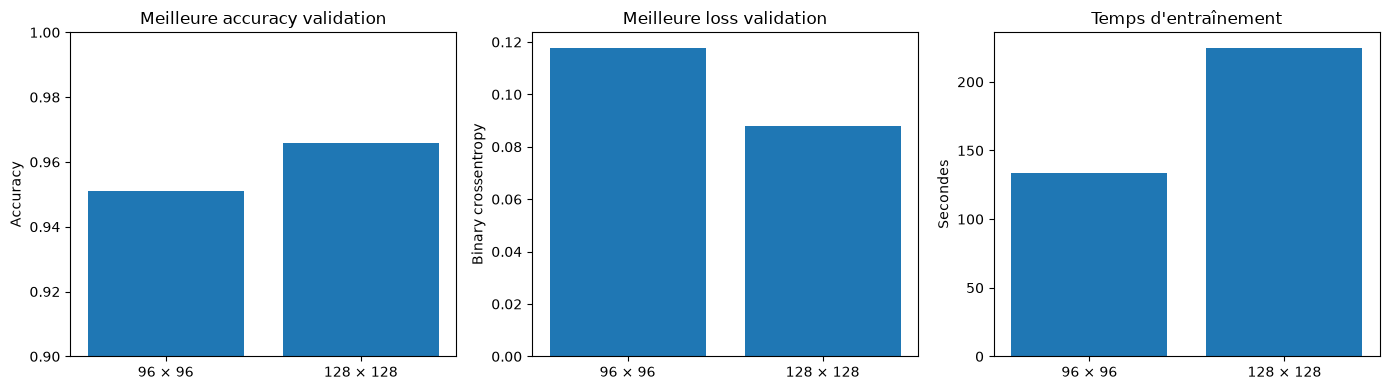

96 × 96
  accuracy=0.951, loss=0.118, temps=133.8 s
128 × 128
  accuracy=0.966, loss=0.088, temps=224.8 s


In [4]:
resolution_names = ["96 × 96", "128 × 128"]
resolution_accuracies = [
    extended_best_accuracy,
    resolution_128_best_accuracy,
]
resolution_losses = [
    extended_best_loss,
    resolution_128_best_loss,
]
resolution_times = [
    extended_seconds,
    resolution_128_seconds,
]

figure, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(resolution_names, resolution_accuracies)
axes[0].set_ylim(0.90, 1.00)
axes[0].set_title("Meilleure accuracy validation")
axes[0].set_ylabel("Accuracy")

axes[1].bar(resolution_names, resolution_losses)
axes[1].set_title("Meilleure loss validation")
axes[1].set_ylabel("Binary crossentropy")

axes[2].bar(resolution_names, resolution_times)
axes[2].set_title("Temps d'entraînement")
axes[2].set_ylabel("Secondes")

plt.tight_layout()
figure.savefig(
    PROJECT_DIR / "artifacts" / "mobilenetv2_resolution_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("96 × 96")
print(
    f"  accuracy={extended_best_accuracy:.3f}, "
    f"loss={extended_best_loss:.3f}, temps={extended_seconds:.1f} s"
)
print("128 × 128")
print(
    f"  accuracy={resolution_128_best_accuracy:.3f}, "
    f"loss={resolution_128_best_loss:.3f}, "
    f"temps={resolution_128_seconds:.1f} s"
)


## 27. Fine-tuning du meilleur modèle en 128 × 128

La résolution `128 × 128` a amélioré le modèle gelé. Nous appliquons maintenant le même fine-tuning que pour `96 × 96` : seules les 20 dernières couches de MobileNetV2 peuvent changer, les Batch Normalization restent figées, et Adam utilise un learning rate très faible de `0.00001`.

Cette étape mesure l'effet combiné de la résolution plus détaillée et de l'adaptation légère des filtres les plus spécialisés. La comparaison reste effectuée uniquement sur la validation.


In [2]:
fine_tune_128_model = keras.models.load_model(
    PROJECT_DIR / "models" / "mobilenetv2_128_frozen_best.keras"
)
fine_tune_128_base = fine_tune_128_model.get_layer(
    "mobilenetv2_1.00_128"
)

fine_tune_128_base.trainable = True
fine_tune_128_at = len(fine_tune_128_base.layers) - 20

for layer_index, layer in enumerate(fine_tune_128_base.layers):
    should_train = layer_index >= fine_tune_128_at
    if isinstance(layer, layers.BatchNormalization):
        should_train = False
    layer.trainable = should_train

fine_tune_128_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
)

fine_tune_128_trainable = sum(
    int(np.prod(variable.shape))
    for variable in fine_tune_128_model.trainable_weights
)
print(
    "Paramètres entraînables après dégel :",
    fine_tune_128_trainable,
)

fine_tune_128_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    min_delta=0.001,
    restore_best_weights=True,
)
fine_tune_128_checkpoint_path = (
    PROJECT_DIR / "models" / "mobilenetv2_128_finetuned_best.keras"
)
fine_tune_128_checkpoint = keras.callbacks.ModelCheckpoint(
    fine_tune_128_checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
)


Paramètres entraînables après dégel : 1196161


In [3]:
fine_tune_128_start = time.perf_counter()
fine_tune_128_history = fine_tune_128_model.fit(
    resolution_128_train_dataset,
    validation_data=resolution_128_validation_dataset,
    epochs=10,
    callbacks=[
        fine_tune_128_early_stopping,
        fine_tune_128_checkpoint,
    ],
    shuffle=False,
    verbose=2,
)
fine_tune_128_seconds = time.perf_counter() - fine_tune_128_start

fine_tune_128_epochs = len(fine_tune_128_history.history["loss"])
fine_tune_128_best_index = int(
    np.argmin(fine_tune_128_history.history["val_loss"])
)
fine_tune_128_best_epoch = fine_tune_128_best_index + 1
fine_tune_128_best_accuracy = fine_tune_128_history.history[
    "val_accuracy"
][fine_tune_128_best_index]
fine_tune_128_best_loss = fine_tune_128_history.history[
    "val_loss"
][fine_tune_128_best_index]

print("Epochs effectuées :", fine_tune_128_epochs)
print("Meilleure epoch selon val_loss :", fine_tune_128_best_epoch)
print(f"Accuracy à cette epoch : {fine_tune_128_best_accuracy:.3f}")
print(f"Loss à cette epoch : {fine_tune_128_best_loss:.3f}")
print(f"Temps total : {fine_tune_128_seconds:.1f} s")


Epoch 1/10


16/16 - 15s - 968ms/step - accuracy: 0.9900 - loss: 0.0444 - val_accuracy: 0.9670 - val_loss: 0.0844


Epoch 2/10


16/16 - 12s - 753ms/step - accuracy: 0.9937 - loss: 0.0306 - val_accuracy: 0.9650 - val_loss: 0.0862


Epoch 3/10


16/16 - 13s - 784ms/step - accuracy: 0.9962 - loss: 0.0243 - val_accuracy: 0.9670 - val_loss: 0.0839


Epochs effectuées : 3
Meilleure epoch selon val_loss : 3
Accuracy à cette epoch : 0.967
Loss à cette epoch : 0.084
Temps total : 40.1 s


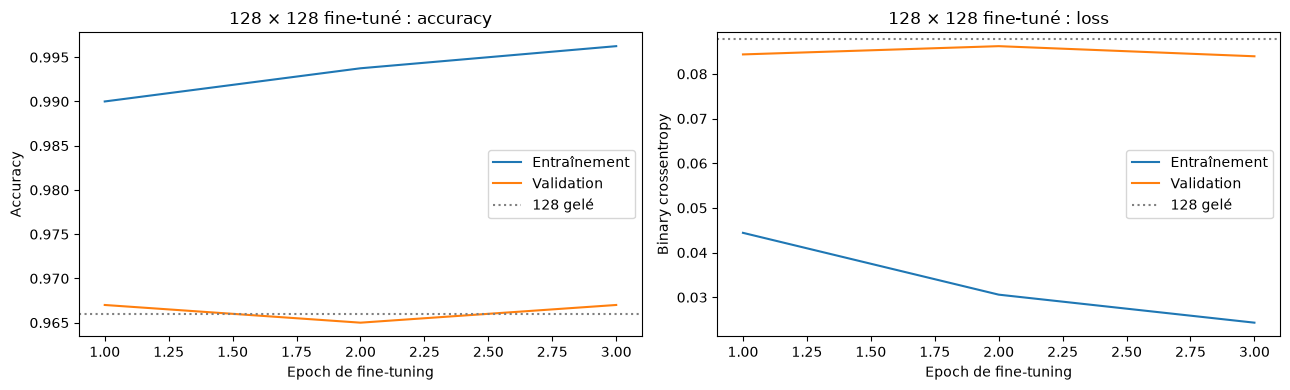

128 gelé
  accuracy=0.966, loss=0.088
128 fine-tuné
  accuracy=0.967, loss=0.084


In [4]:
fine_tune_128_axis = range(1, fine_tune_128_epochs + 1)
figure, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    fine_tune_128_axis,
    fine_tune_128_history.history["accuracy"],
    label="Entraînement",
)
axes[0].plot(
    fine_tune_128_axis,
    fine_tune_128_history.history["val_accuracy"],
    label="Validation",
)
axes[0].axhline(
    resolution_128_best_accuracy,
    color="grey",
    linestyle=":",
    label="128 gelé",
)
axes[0].set_title("128 × 128 fine-tuné : accuracy")
axes[0].set_xlabel("Epoch de fine-tuning")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    fine_tune_128_axis,
    fine_tune_128_history.history["loss"],
    label="Entraînement",
)
axes[1].plot(
    fine_tune_128_axis,
    fine_tune_128_history.history["val_loss"],
    label="Validation",
)
axes[1].axhline(
    resolution_128_best_loss,
    color="grey",
    linestyle=":",
    label="128 gelé",
)
axes[1].set_title("128 × 128 fine-tuné : loss")
axes[1].set_xlabel("Epoch de fine-tuning")
axes[1].set_ylabel("Binary crossentropy")
axes[1].legend()

plt.tight_layout()
figure.savefig(
    PROJECT_DIR / "artifacts" / "mobilenetv2_128_finetuning.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("128 gelé")
print(
    f"  accuracy={resolution_128_best_accuracy:.3f}, "
    f"loss={resolution_128_best_loss:.3f}"
)
print("128 fine-tuné")
print(
    f"  accuracy={fine_tune_128_best_accuracy:.3f}, "
    f"loss={fine_tune_128_best_loss:.3f}"
)


### Conclusion de la comparaison des résolutions

Pour MobileNetV2, passer de `96 × 96` à `128 × 128` a produit le gain principal : l'accuracy de validation passe de **95,1 % à 96,6 %** et la loss de **0,118 à 0,088**. En contrepartie, le temps passe d'environ **134 à 225 secondes**, soit une hausse d'environ 68 %.

Le fine-tuning du modèle `128 × 128` apporte ensuite seulement **0,1 point** supplémentaire, avec **96,7 %** d'accuracy et **0,084** de loss. L'entraînement dépasse déjà 99 % d'accuracy et l'arrêt anticipé intervient après 3 epochs : les rendements deviennent faibles et le risque de mémorisation augmente.

La conclusion défendable est donc que MobileNetV2 profite ici des détails supplémentaires de `128 × 128`, tandis que le fine-tuning apporte peu après le bon entraînement de la tête. Ces expériences étant postérieures à l'ouverture du test final, elles restent exploratoires et ne modifient pas le score de test officiel de **94,3 %**.